<a href="https://colab.research.google.com/github/jedissica-rds/RNA2/blob/main/rna_2026_2_pp2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Bibliotecas**

Fazendo uso das bibliotecas numpy,
random, math e matplotlib. Em particular, a biblioteca numpy será de uso obrigatório para todas
as operações de natureza matricial (multiplicação de matrizes, produto escalar, etc). Neste projeto
prático

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
import random
import itertools
import pandas as pd
from prettytable import PrettyTable
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn import datasets

**Função de Ativação**

In [ ]:
def unit_step_func(x):
  return np.where(x >= 0, 1, 0)

**Dataset**

In [ ]:
data = np.load("sample_data/dataAll20262.txt", allow_pickle=False)

data = data.reshape(-1, 3)

X = data[:, :2]
y = data[:, 2].astype(int)

**Classe do Neurônio Perceptron**

**Testes**

In [ ]:
class Perceptron:

  def __init__(self, learning_rate=0.1,n_iters=1000, max_epochs=10000, low=-0.5, high=0.5, shuffle=False, stop_on_convergence=True, seed=None, verbose=False):
    self.lr = learning_rate
    self.n_iters = n_iters
    self.activation_func = unit_step_func
    self.weights = None
    self.bias = None
    self.stop_on_convergence = stop_on_convergence
    self.rng= np.random.default_rng(seed)
    self.low, self.high = low, high
    self.verbose = verbose
    self.n_updates = 0
    self.n_epochs = 0
    self.converged = False
    self.shuffle = shuffle
    self.max_epochs = max_epochs

  def fit(self, X, y):
    n_samples, n_features = X.shape
    y_ = np.where(y > 0, 1, 0)

    self.weights = self.rng.uniform(self.low, self.high, size=n_features)
    self.bias = self.rng.uniform(self.low, self.high)


    if self.verbose:
      print(f"Pesos iniciais: {np.round(self.weights, 2).tolist()}, "
        f"bias={self.bias:.3f}")

    self.n_updates = 0
    self.n_epochs = 0
    self.converged = False

    #learn weights

    self.history = []

    for epoch in range(self.max_epochs):
      errors = 0
      order = self.rng.permutation(n_samples) if self.shuffle \
              else np.arange(n_samples)

      for idx in order:
        x_i = X[idx]
        y_i = y[idx]

        linear_output = np.dot(x_i, self.weights) + self.bias
        y_predicted = self.activation_func(linear_output)

        #Percpetion update rule

        update = self.lr * (y_[idx] - y_predicted)

        if update != 0:
          self.weights += update * x_i
          self.bias += update
          self.n_updates += 1
          errors += 1

      self.n_epochs += 1
      self.history.append(errors)

      if errors == 0:
        self.converged = True
        if self.stop_on_convergence:
          break

    if self.verbose:
      print("Total de ajustes:", self.n_updates)
      print("Total de épocas:", self.n_epochs)
      if not self.converged:
        print("Não convergiu")

    return self

  def predict(self, X):
    linear_output = np.dot(X, self.weights) + self.bias
    y_predicted = self.activation_func(linear_output)

    return y_predicted

In [ ]:
def accuracy(y_true, y_pred):
  accuracy = np.sum(y_true == y_pred) / len(y_true)
  return accuracy

Pesos iniciais: [0.43, -0.06], bias=-0.239
Total de ajustes: 42
Total de épocas: 3


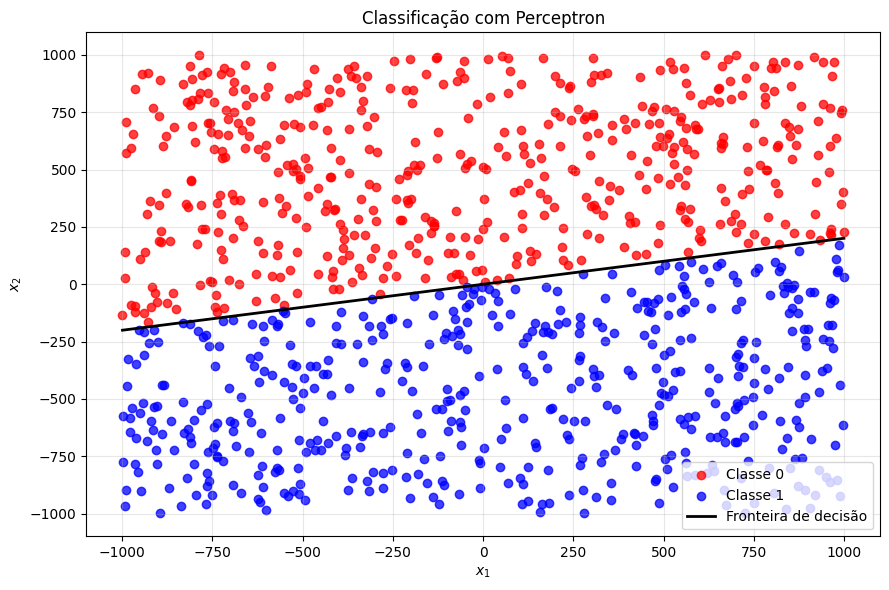

In [ ]:
p = Perceptron(learning_rate=0.1, max_epochs=10000, verbose=True)
p.fit(X, y)
predictions = p.predict(X)
errors = np.sum(predictions != y)

fig, ax = plt.subplots(figsize=(9, 6))

# vermelho
ax.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    color="red",
    marker="o",
    label="Classe 0",
    alpha=0.75
)

#azul
ax.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    marker="o",
    label="Classe 1",
    alpha=0.75
)

w1, w2 = p.weights
b = p.bias

x_min = X[:, 0].min()
x_max = X[:, 0].max()


if not np.isclose(w2, 0):
    x_line = np.linspace(x_min, x_max, 200)
    y_line = -(w1 * x_line + b) / w2

    ax.plot(
        x_line,
        y_line,
        color="black",
        linewidth=2,
        label="Fronteira de decisão"
    )


elif not np.isclose(w1, 0):
    x_vertical = -b / w1
    ax.axvline(
        x=x_vertical,
        color="black",
        linewidth=2,
        label="Fronteira de decisão"
    )

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Classificação com Perceptron")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Experimentação

In [ ]:
id_team = 0
data_e = np.load("sample_data/data020262.txt", allow_pickle=False).reshape(-1, 3)
Xe = data_e[:, :2]
ye = data_e[:, 2].astype(int)

In [ ]:
Xs = Xe / 1000        # dados divididos por 1000

results = {}
configs = list(itertools.product([0.4, 0.1, 0.01], [(-100, 100), (-0.5, 0.5)]))
for k, (eta, (lo, hi)) in enumerate(configs):
  runs = []
  for rep in range(10):
    p = Perceptron(learning_rate=eta, low=lo, high=hi,
                   max_epochs=5000, seed=100 * k + rep).fit(Xs, ye)
    runs.append((p.n_updates, p.n_epochs, p.converged))
  results[(eta, lo, hi)] = runs
  print(f"config {k + 1}/6 pronta: η={eta}, ({lo},{hi}) | "
        f"convergiram: {sum(r[2] for r in runs)}/10")

config 1/6 pronta: η=0.4, (-100,100) | convergiram: 10/10
config 2/6 pronta: η=0.4, (-0.5,0.5) | convergiram: 10/10
config 3/6 pronta: η=0.1, (-100,100) | convergiram: 10/10
config 4/6 pronta: η=0.1, (-0.5,0.5) | convergiram: 10/10
config 5/6 pronta: η=0.01, (-100,100) | convergiram: 10/10
config 6/6 pronta: η=0.01, (-0.5,0.5) | convergiram: 10/10


In [ ]:
# tabela de aprendizado e etc...
tabela = PrettyTable()
tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos",
                      "Qtde Ajustes", "Min Épocas", "Max Épocas", "Não convergiu"]
for (eta, lo, hi), r in results.items():
    r = np.array(r, dtype=float)
    aj, ep, conv = r[:, 0], r[:, 1], r[:, 2]
    tabela.add_row([f"η = {eta}", f"({lo}, +{hi})",
                    f"{aj.mean():.2f} ± {aj.std():.2f}",
                    int(ep.min()), int(ep.max()), int((conv == 0).sum())])
print(tabela)

+---------------------+--------------------+--------------------+------------+------------+---------------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes    | Min Épocas | Max Épocas | Não convergiu |
+---------------------+--------------------+--------------------+------------+------------+---------------+
|       η = 0.4       |    (-100, +100)    |  607.50 ± 433.36   |     7      |    592     |       0       |
|       η = 0.4       |    (-0.5, +0.5)    |  656.60 ± 494.67   |     4      |    186     |       0       |
|       η = 0.1       |    (-100, +100)    |  1078.70 ± 199.47  |     7      |     31     |       0       |
|       η = 0.1       |    (-0.5, +0.5)    |  614.90 ± 294.92   |     9      |    114     |       0       |
|       η = 0.01      |    (-100, +100)    | 12975.00 ± 5449.51 |     33     |    298     |       0       |
|       η = 0.01      |    (-0.5, +0.5)    |  574.50 ± 218.10   |     11     |    298     |       0       |
+---------------------+-----

In [ ]:
# tabela de medianas
t2 = PrettyTable(["Configuração", "Mediana ajustes", "Q1–Q3 ajustes",
                  "Mediana épocas", "Q1–Q3 épocas"])
for (eta, lo, hi), r in results.items():
    r = np.array(r, dtype=float)
    a = np.percentile(r[:, 0], [25, 50, 75])
    e = np.percentile(r[:, 1], [25, 50, 75])
    t2.add_row([f"η={eta}, ({lo},{hi})", f"{a[1]:.1f}", f"{a[0]:.1f}–{a[2]:.1f}",
                f"{e[1]:.1f}", f"{e[0]:.1f}–{e[2]:.1f}"])
print(t2)

+--------------------+-----------------+----------------+----------------+--------------+
|    Configuração    | Mediana ajustes | Q1–Q3 ajustes  | Mediana épocas | Q1–Q3 épocas |
+--------------------+-----------------+----------------+----------------+--------------+
| η=0.4, (-100,100)  |      468.0      |  342.5–764.8   |      20.5      |  9.2–138.0   |
| η=0.4, (-0.5,0.5)  |      418.5      |  317.0–837.8   |      24.0      |  16.0–65.8   |
| η=0.1, (-100,100)  |      1144.5     |  918.5–1188.8  |      26.0      |  14.2–27.5   |
| η=0.1, (-0.5,0.5)  |      480.5      |  448.2–872.0   |      27.0      |  26.0–72.8   |
| η=0.01, (-100,100) |     13856.0     | 8272.0–17023.8 |     113.5      |  57.2–189.5  |
| η=0.01, (-0.5,0.5) |      503.0      |  430.2–746.2   |      61.0      |  25.0–93.2   |
+--------------------+-----------------+----------------+----------------+--------------+


Ao treinar o perceptron em sua escala original, o algoritmo não conseguia convergir. Os pontos tem coordernadas entre aprox. -1000 e +1000, e os testes realizados foram:


*   60 execuções da parte II (6 configurações x 10 repetições) com limite de 300 épocas, com isso, o resultado retornado foi de *0 de 60 convergiram*
*   Uma execução longa de *20.000 épocas* (η = 0,1, 208 s): também não convergiu. O número médio de erros por época caiu lentamente (56,1 → 34,5 → 25,2 → 18,0 em blocos de 1.000 épocas, com mínimo de 5 erros em uma época), mostrando que o treino progredia, mas de forma muito lenta.
* Uma verificação por programação linear também foi feita (fora do notebook) com o conjunto de dados para ter a confirmação de que ele é linearmente seprável (se confirmou).

Com isso, como as coordenadas são de ordem 1000, cada correção altera os pesos em η·x (que são valores grandes), mas altera o bias em apenas η, porque a entrada que fica associada a ele é 1. O bias, que desloca a reta, é então ajustado cerca de mil vezes mais devagar que os pesos, o que atrasa muito a convergência. Dividir todas as coordenadas por uma constante (1000) foi a solução mais fácil e não prejudicial encontrada, visto que ela não altera os rótulos nem a separabilidade das classes, e apenas reequilibra essas escalas. Após a divisão, uma execução de teste (η = 0,1; pesos em U(−0,5, +0,5)) convergiu em *31 épocas*, com 539 ajustes.

Então, como a escala dos dados mudaram, as conclusões sobre a taxa de aprendizado e o intervalo dos pesos referem-se aos dados divididos por 1000.



## holdout


In [ ]:
dados = np.load("sample_data/dataHoldout20262.txt", allow_pickle=False)
dados = dados.reshape(-1, 3)
Xh = dados[:, :2]
yh = dados[:, 2].astype(int)

df = pd.DataFrame({"x1": Xh[:, 0], "x2": Xh[:, 1], "y": yh})

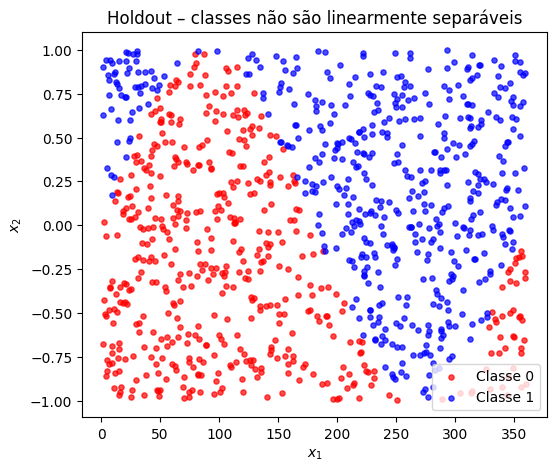

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for classe, cor in [(0, "red"), (1, "blue")]:
    sub = df[df["y"] == classe]
    ax.scatter(sub["x1"], sub["x2"], c=cor, s=14, alpha=.7, label=f"Classe {classe}")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Holdout – classes não são linearmente separáveis")
ax.legend(); plt.show()

In [ ]:
rng = np.random.default_rng(id_team)
idx = rng.permutation(len(Xh))
cut = int(0.7 * len(Xh))
X_tr, y_tr = Xh[idx[:cut]], yh[idx[:cut]]
X_te, y_te = Xh[idx[cut:]], yh[idx[cut:]]
print(f"Treino: {len(X_tr)} | Teste: {len(X_te)}")

Treino: 700 | Teste: 300


In [ ]:
p3 = Perceptron(learning_rate=0.1, max_epochs=100, low=-0.5, high=0.5,
                shuffle=True, stop_on_convergence=False,
                seed=id_team, verbose=True)
p3.fit(X_tr, y_tr)

y_pred_tr = p3.predict(X_tr)
y_pred_te = p3.predict(X_te)

Pesos iniciais: [0.14, -0.23], bias=-0.459
Total de ajustes: 29707
Total de épocas: 100
Não convergiu


In [ ]:
#métricas
tm = PrettyTable(["Conjunto", "Acurácia", "Precisão", "Revocação", "F-Score"])
for name, yt, yp in [("Treino", y_tr, y_pred_tr), ("Teste", y_te, y_pred_te)]:
    tm.add_row([name,
                f"{accuracy_score(yt, yp):.4f}",
                f"{precision_score(yt, yp, zero_division=0):.4f}",
                f"{recall_score(yt, yp, zero_division=0):.4f}",
                f"{f1_score(yt, yp, zero_division=0):.4f}"])
print(tm)

+----------+----------+----------+-----------+---------+
| Conjunto | Acurácia | Precisão | Revocação | F-Score |
+----------+----------+----------+-----------+---------+
|  Treino  |  0.7429  |  0.6748  |   0.9432  |  0.7867 |
|  Teste   |  0.7667  |  0.7067  |   0.9423  |  0.8077 |
+----------+----------+----------+-----------+---------+


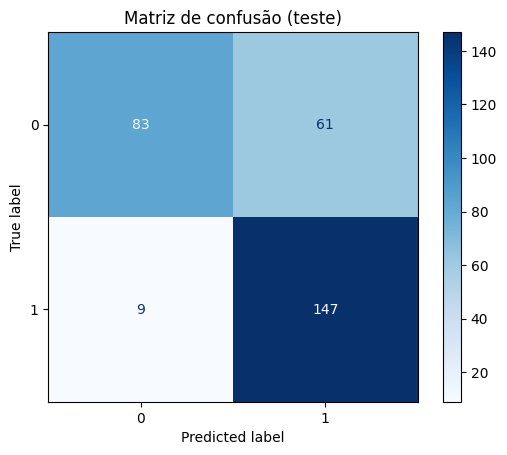

In [ ]:
#matriz de confusão
cm = confusion_matrix(y_te, y_pred_te, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.show()

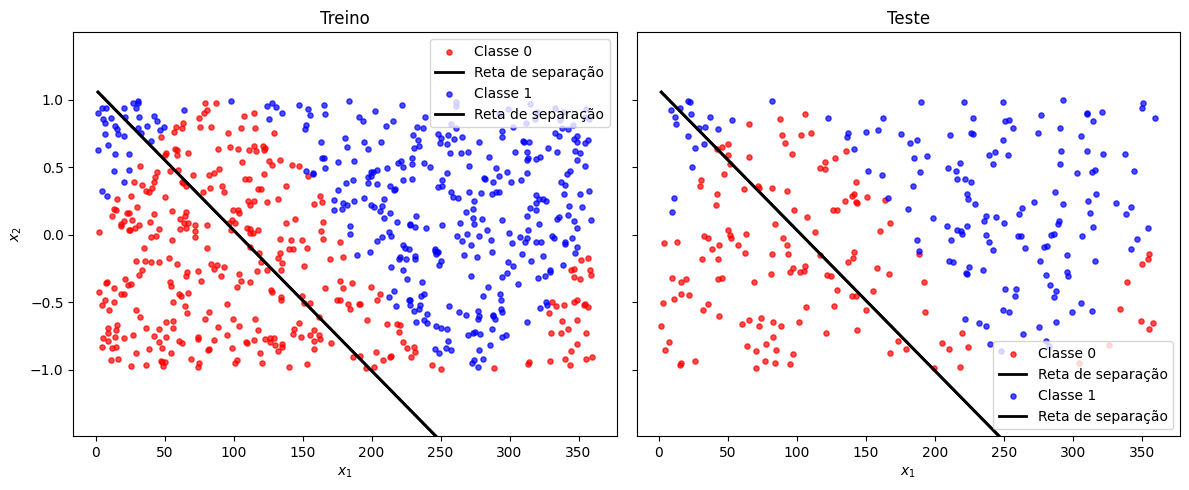

In [ ]:
w1, w2 = p3.weights
b = p3.bias
x1 = np.array([Xh[:, 0].min(), Xh[:, 0].max()])

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, name, Xs, ys in zip(ax, ["Treino", "Teste"], [X_tr, X_te], [y_tr, y_te]):
    for classe, cor in [(0, "red"), (1, "blue")]:
        a.scatter(Xs[ys == classe, 0], Xs[ys == classe, 1], c=cor, s=14, alpha=.7, label=f"Classe {classe}")
        a.plot(x1, -(w1 * x1 + b) / w2, "k-", lw=2, label="Reta de separação")
    a.set_title(name); a.set_xlabel("$x_1$"); a.legend()

ax[0].set_ylabel("$x_2$")
ax[0].set_ylim(Xh[:, 1].min() - 0.5, Xh[:, 1].max() + 0.5)
plt.tight_layout(); plt.show()

# Boxplots


In [ ]:
results = {k: np.array(v, dtype=float) for k, v in results.items()}

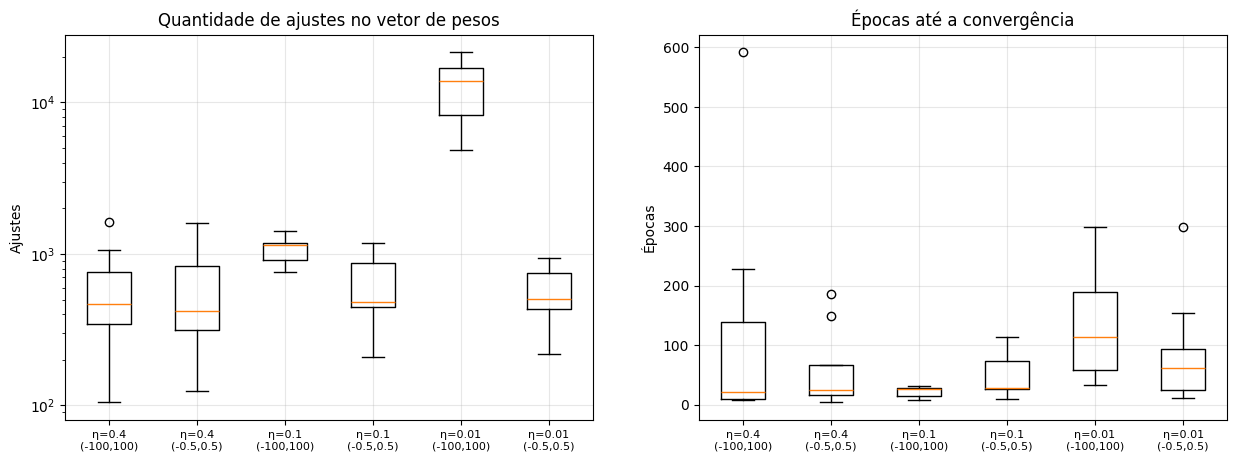

In [ ]:
rotulos = [f"η={eta}\n({lo},{hi})" for (eta, lo, hi) in results]
metricas = [("Quantidade de ajustes no vetor de pesos", "Ajustes", 0),
            ("Épocas até a convergência", "Épocas", 1)]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, (titulo, ylabel, col) in zip(ax, metricas):
    a.boxplot([r[:, col] for r in results.values()])
    a.set_xticklabels(rotulos, fontsize=8)
    if col == 0:
        a.set_yscale("log")
    a.set_title(titulo); a.set_ylabel(ylabel); a.grid(alpha=.3)

Todas as 60 execuções convergiram. Pelos boxplots e pelas medianas, não há uma única configuração melhor que as demais, mas há uma claramente pior. Com η = 0,01 e pesos em (−100, +100), o neurônio precisou de uma mediana de 13.856 ajustes, de 20 a 30 vezes mais que as outras, e o intervalo interquartil não se sobrepõe ao de nenhum delas. A configuração η = 0,1 com (−100, +100) também exigiu mais ajustes (mediana de 1.144,5), mas com baixa dispersão e poucas épocas (7 a 31). As quatro configurações restantes apresentaram medianas entre 418 e 503 ajustes, com caixas sobrepostas, e podem ser consideradas equivalentes. O padrão é explicado pela razão entre η e a escala dos pesos iniciais: como a ativação degrau, só essa razão importa, e quando ela é muito pequena as correções são minúsculas em relação aos pesos sorteados, exigindo muitas atualizações. Quanto às épocas, as medianas ficaram entre 20 e 27 para quatro configurações e foram maiores com η = 0,01, mas com grande sobreposição. As médias têm desvios altos por execuções atípicas, e o número de repetições é pequeno (10), então a conclusão é indicativa. Os dados foram divididos por 1000 antes do treino.

## 4. A partir destas métricas, discorra acerca da qualidade desta solução perante o conjunto de testes.






A solução obtida é de qualidade limitada. No conjunto de teste de 300 exemplos, o neurônio alcançou acurácia de 67,67% (com 64% no treino), precisão de 61,94%, revocação de 98.08% e F-Score de 75,93%. A revocação elevada e a precisão baixa indicam que o neurônio tende a prever a classe 1, fazendo com que ele atribuiu a cerca de 81% dos exemplos de teste, produzindo muitos falsos positivos e poucos falsos negativos, o que é considerado favorável em ambientes de decisão. Assim, o F-Score elevado esconde que a taxa de acerto na classe 0 é baixa, e a acurácia de 68% supera apenas moderadamente a de um classificador que sempre prevê a classe majoritária (52%). A proximidade entre os resultados de treino e de teste indica a ausência de overfitting; a limitação decorre de o problema não ser linearmente separável, o que impede a convergência do perceptron: houve 27.063 ajustes em 100 épocas, e os pesos finais, os da última época, apenas oscilam em torno de uma reta que não separa as classes. Para melhorar, seria preciso guardar os melhores pesos observados durante o treino.
